# Eksplorasi dan Preprocessing Dataset Hoaks Komdigi

Notebook ini menggunakan `komdigi_hoaks.csv` untuk mengeksplorasi artikel klarifikasi hoaks, melihat distribusi topik dan fitur numerik, menangani data kosong/duplikat, serta menyiapkan teks dan fitur numerik untuk analisis lanjutan.

Kolom `topics` digunakan sebagai label topik artikel. Kolom `category` tidak digunakan sebagai label karena seluruh data memiliki kategori yang sama. Label topik tidak menunjukkan apakah klaim benar atau salah.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

# Mendukung eksekusi dari root repository maupun folder notebook.
data_candidates = [
    Path("data/komdigi_hoaks.csv"),
    Path("../data/komdigi_hoaks.csv"),
    Path("../../data/komdigi_hoaks.csv"),
    Path("../../../data/komdigi_hoaks.csv"),
]
data_path = next((path for path in data_candidates if path.is_file()), None)
if data_path is None:
    raise FileNotFoundError(
        "File komdigi_hoaks.csv tidak ditemukan. Periksa lokasi folder data."
    )

df = pd.read_csv(data_path)
df["published_at"] = pd.to_datetime(df["published_at"], errors="coerce")
df["title_length"] = df["title"].fillna("").str.len()
df["body_length"] = df["body_text"].fillna("").str.len()

print(f"Lokasi dataset: {data_path.resolve()}")
print(f"Ukuran dataset: {df.shape[0]} baris dan {df.shape[1]} kolom")
display(df.head())
df.info()
display(df.isna().sum().rename("jumlah_missing").to_frame())
display(df.describe(include="all").T)

Lokasi dataset: D:\Kuliah\Kelas\Semester 5\Pembelajaran Mesin\TUGAS\PRAKTIKUM\data\komdigi_hoaks.csv
Ukuran dataset: 4176 baris dan 15 kolom


,id,url,title,slug,published_at,view_count,excerpt,body_html,body_text,main_image_url,category,tags,topics,title_length,body_length
0,65399,https://www.komdigi.go.id/berita/berita-hoaks/...,[HOAKS] Tautan Pencairan BSU September 2026 Se...,hoaks-tautan-pencairan-bsu-september-2026-sebe...,2026-09-27 23:03:00,272,Kepala Biro Humas Kementerian Ketenagakerjaan ...,"<p style=""margin-left:0in;text-align:justify;""...",Penjelasan: Beredar sebuah unggahan berisi tau...,https://web.komdigi.go.id/resource/dXBsb2Fkcy8...,Klarifikasi Hoaks,hoaks hari ini,Hoaks,61,1061
1,65398,https://www.komdigi.go.id/berita/berita-hoaks/...,[HOAKS] Panas El Nino Berkaitan dengan Gelomba...,hoaks-panas-el-nino-berkaitan-dengan-gelombang...,2026-09-27 23:02:00,156,El Nino merupakan fenomena alam yang terjadi a...,"<p style=""margin-left:0in;text-align:justify;""...",Penjelasan: Beredar unggahan di media sosial I...,https://web.komdigi.go.id/resource/dXBsb2Fkcy8...,Klarifikasi Hoaks,hoaks hari ini,Hoaks,64,1179
2,65397,https://www.komdigi.go.id/berita/berita-hoaks/...,[HOAKS] Susu Bebelac Berbahaya karena Mengandu...,hoaks-susu-bebelac-berbahaya-karena-mengandung...,2026-09-27 23:01:00,146,Maltodekstrin merupakan bahan tambahan pangan ...,"<p style=""margin-left:0in;text-align:justify;""...",Penjelasan: Beredar unggahan di media sosial T...,https://web.komdigi.go.id/resource/dXBsb2Fkcy8...,Klarifikasi Hoaks,hoaks hari ini,Hoaks,62,1992
3,65392,https://www.komdigi.go.id/berita/berita-hoaks/...,[HOAKS] Purbaya Informasikan Raffi Ahmad Beli ...,hoaks-purbaya-informasikan-raffi-ahmad-beli-ko...,2026-09-26 23:04:00,224,NaN,<p>Penjelasan: &nbsp;</p><p>Beredar sebuah ung...,Penjelasan: Beredar sebuah unggahan video di m...,https://web.komdigi.go.id/resource/dXBsb2Fkcy8...,Klarifikasi Hoaks,hoaks hari ini,Hoaks,81,749
4,65391,https://www.komdigi.go.id/berita/berita-hoaks/...,[HOAKS] Tautan Bantuan Laptop dan Ponsel untuk...,hoaks-tautan-bantuan-laptop-dan-ponsel-untuk-m...,2026-09-26 23:02:00,309,NaN,<p>Penjelasan: &nbsp;</p><p>Beredar unggahan d...,Penjelasan: Beredar unggahan di media sosial F...,https://web.komdigi.go.id/resource/dXBsb2Fkcy8...,Klarifikasi Hoaks,hoaks hari ini,Hoaks,56,1025


<class 'pandas.DataFrame'>
RangeIndex: 4176 entries, 0 to 4175
Data columns (total 15 columns):
 #   Column          Non-Null Count  Dtype         
---  ------          --------------  -----         
 0   id              4176 non-null   int64         
 1   url             4176 non-null   str           
 2   title           4176 non-null   str           
 3   slug            4176 non-null   str           
 4   published_at    4176 non-null   datetime64[us]
 5   view_count      4176 non-null   int64         
 6   excerpt         1293 non-null   str           
 7   body_html       4176 non-null   str           
 8   body_text       4176 non-null   str           
 9   main_image_url  4171 non-null   str           
 10  category        4176 non-null   str           
 11  tags            2193 non-null   str           
 12  topics          4176 non-null   str           
 13  title_length    4176 non-null   int64         
 14  body_length     4176 non-null   int64         
dtypes: datetime64[u

,jumlah_missing
id,0
url,0
title,0
slug,0
published_at,0
view_count,0
excerpt,2883
body_html,0
body_text,0
main_image_url,5


,count,unique,top,freq,mean,min,25%,50%,75%,max,std
id,4176.0,NaN,NaN,NaN,53908.322557,8.0,58192.75,60893.5,63042.75,65399.0,19948.084958
url,4176,4162,https://www.komdigi.go.id/berita/berita-hoaks/...,2,NaN,NaN,NaN,NaN,NaN,NaN,NaN
title,4176,4162,[HOAKS] Purbaya Minta Dukungan Bongkar Korupsi...,2,NaN,NaN,NaN,NaN,NaN,NaN,NaN
slug,4176,4162,hoaks-purbaya-minta-dukungan-bongkar-korupsi-s...,2,NaN,NaN,NaN,NaN,NaN,NaN,NaN
published_at,4176,NaN,NaN,NaN,2025-06-28 22:04:29.158525,2024-05-02 05:15:20,2024-11-01 23:01:45,2025-06-27 23:00:00,2026-02-06 05:18:00,2026-09-27 23:03:00,NaN
view_count,4176.0,NaN,NaN,NaN,1034.817529,0.0,350.0,535.5,878.0,65813.0,2351.36326
excerpt,1293,1285,Audio dalam video yang beredar terindikasi kua...,4,NaN,NaN,NaN,NaN,NaN,NaN,NaN
body_html,4176,4170,"<p style=""margin-left:0in;text-align:justify;""...",2,NaN,NaN,NaN,NaN,NaN,NaN,NaN
body_text,4176,4169,Penjelasan: Beredar sebuah unggahan video di m...,2,NaN,NaN,NaN,NaN,NaN,NaN,NaN
main_image_url,4171,4171,https://web.komdigi.go.id/resource/dXBsb2Fkcy8...,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN


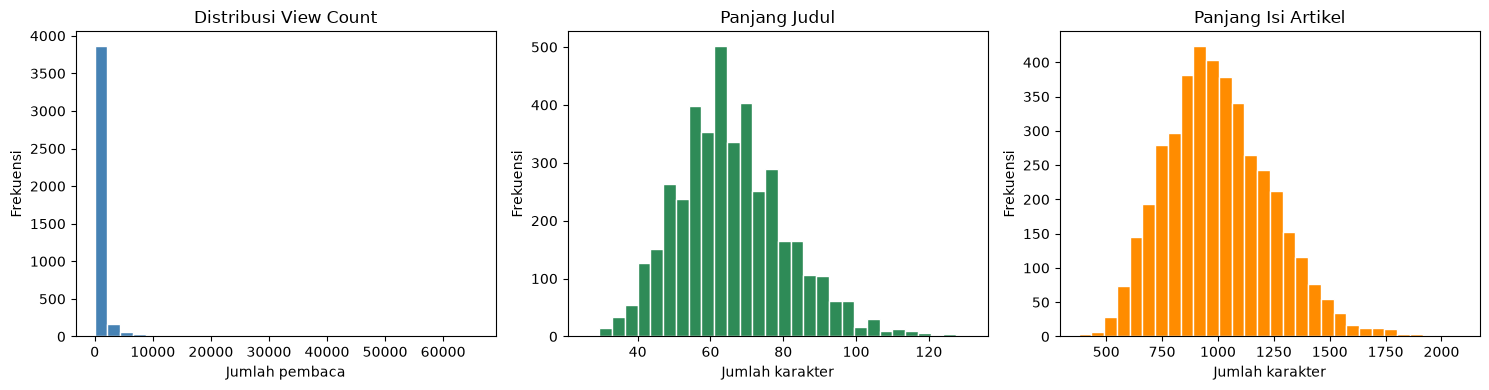

In [2]:
# Distribusi jumlah pembaca dan panjang teks artikel.
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

axes[0].hist(df["view_count"], bins=30, color="steelblue", edgecolor="white")
axes[0].set_title("Distribusi View Count")
axes[0].set_xlabel("Jumlah pembaca")
axes[0].set_ylabel("Frekuensi")

axes[1].hist(df["title_length"], bins=30, color="seagreen", edgecolor="white")
axes[1].set_title("Panjang Judul")
axes[1].set_xlabel("Jumlah karakter")
axes[1].set_ylabel("Frekuensi")

axes[2].hist(df["body_length"], bins=30, color="darkorange", edgecolor="white")
axes[2].set_title("Panjang Isi Artikel")
axes[2].set_xlabel("Jumlah karakter")
axes[2].set_ylabel("Frekuensi")

plt.tight_layout()
plt.show()

C:\Users\qulbiazzumi\AppData\Local\Temp\ipykernel_12344\2897018320.py:3: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  plt.boxplot(np.log1p(df["view_count"].dropna()), vert=False)


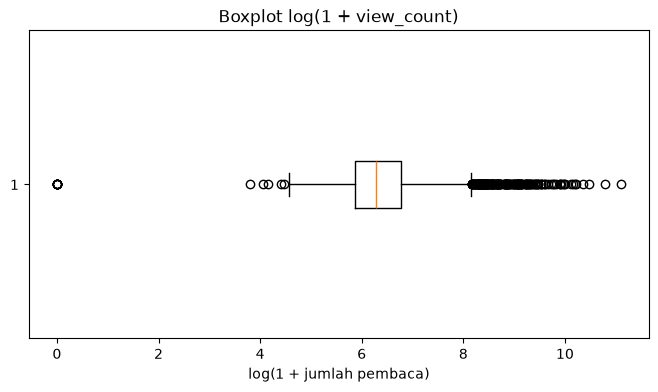

In [3]:
# View count memiliki rentang yang lebar; gunakan log1p agar pencilan lebih mudah diamati.
plt.figure(figsize=(8, 4))
plt.boxplot(np.log1p(df["view_count"].dropna()), vert=False)
plt.title("Boxplot log(1 + view_count)")
plt.xlabel("log(1 + jumlah pembaca)")
plt.show()

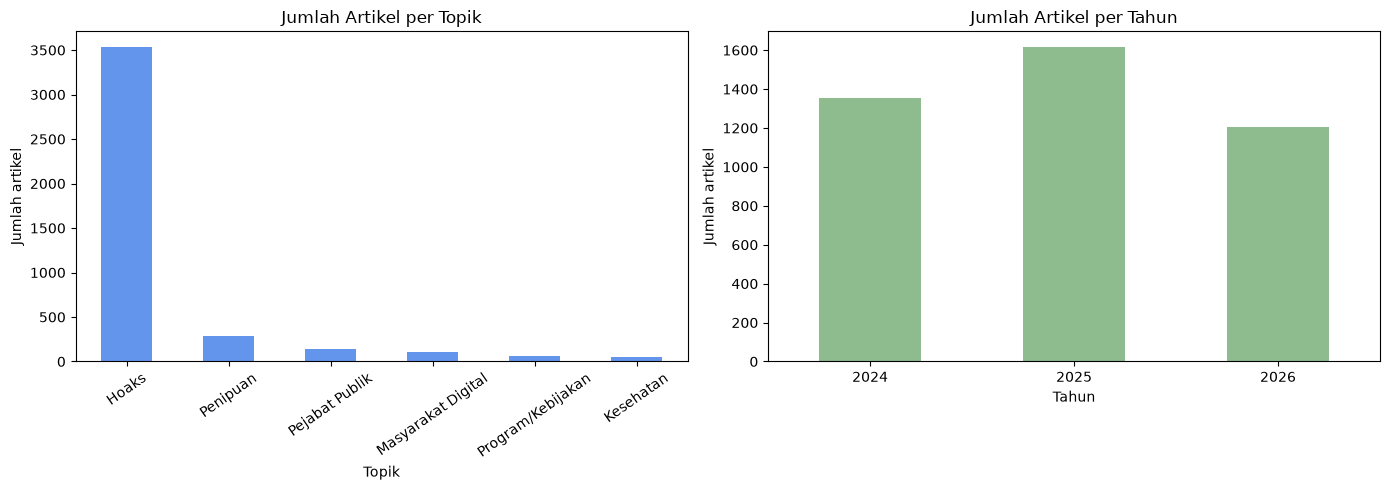

In [4]:
# Distribusi topik dan jumlah artikel per tahun publikasi.
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

df["topics"].value_counts().plot(kind="bar", ax=axes[0], color="cornflowerblue")
axes[0].set_title("Jumlah Artikel per Topik")
axes[0].set_xlabel("Topik")
axes[0].set_ylabel("Jumlah artikel")
axes[0].tick_params(axis="x", rotation=35)

year_counts = df["published_at"].dt.year.value_counts().sort_index()
year_counts.plot(kind="bar", ax=axes[1], color="darkseagreen")
axes[1].set_title("Jumlah Artikel per Tahun")
axes[1].set_xlabel("Tahun")
axes[1].set_ylabel("Jumlah artikel")
axes[1].tick_params(axis="x", rotation=0)

plt.tight_layout()
plt.show()

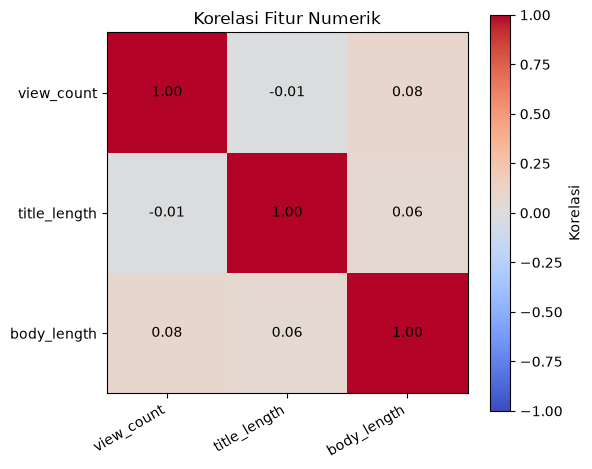

In [5]:
# Korelasi antarfitur numerik, bukan hubungan sebab-akibat.
numeric_columns = ["view_count", "title_length", "body_length"]
corr = df[numeric_columns].corr()

fig, ax = plt.subplots(figsize=(6, 5))
image = ax.imshow(corr, cmap="coolwarm", vmin=-1, vmax=1)
ax.set_xticks(range(len(corr.columns)), labels=corr.columns, rotation=30, ha="right")
ax.set_yticks(range(len(corr.index)), labels=corr.index)
for row in range(len(corr.index)):
    for col in range(len(corr.columns)):
        ax.text(col, row, f"{corr.iloc[row, col]:.2f}", ha="center", va="center")
fig.colorbar(image, ax=ax, label="Korelasi")
ax.set_title("Korelasi Fitur Numerik")
plt.tight_layout()
plt.show()

In [6]:
# Ringkasan label. Kategori sumber bukan target karena nilainya hanya satu kelas.
topic_counts = df["topics"].value_counts()
topic_summary = pd.DataFrame({
    "jumlah_artikel": topic_counts,
    "persentase": (topic_counts / len(df) * 100).round(2),
})
display(topic_summary)
print("Jumlah nilai unik category:", df["category"].nunique())
display(df["category"].value_counts().to_frame("jumlah_artikel"))

,jumlah_artikel,persentase
topics,,
Hoaks,3534,84.63
Penipuan,288,6.90
Pejabat Publik,137,3.28
Masyarakat Digital,102,2.44
Program/Kebijakan,59,1.41
Kesehatan,56,1.34


Jumlah nilai unik category: 1


,jumlah_artikel
category,
Klarifikasi Hoaks,4176


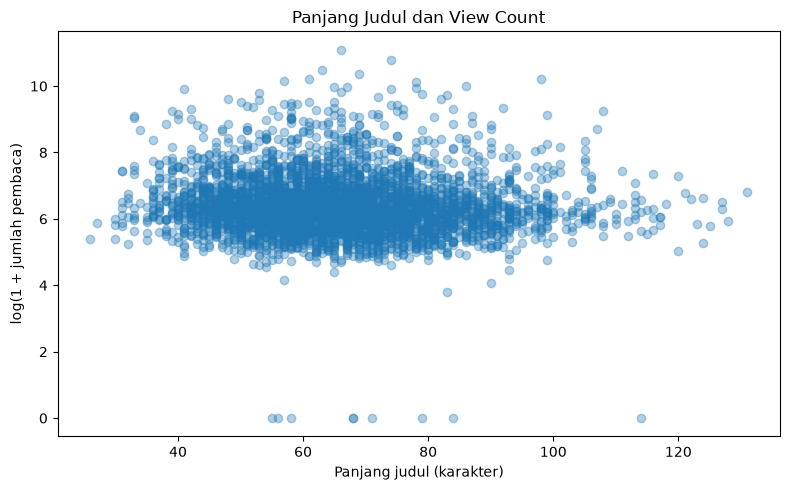

In [7]:
# Perbandingan panjang judul dengan popularitas artikel.
plt.figure(figsize=(8, 5))
plt.scatter(df["title_length"], np.log1p(df["view_count"]), alpha=0.35)
plt.xlabel("Panjang judul (karakter)")
plt.ylabel("log(1 + jumlah pembaca)")
plt.title("Panjang Judul dan View Count")
plt.tight_layout()
plt.show()

In [8]:
# Tangani duplikat berdasarkan URL dan isi kosong pada kolom teks opsional.
df_clean = df.drop_duplicates(subset="url", keep="first").copy()
for column in ["excerpt", "tags"]:
    df_clean[column] = df_clean[column].fillna("")

df_clean["topics"] = df_clean["topics"].str.strip()
df_clean["article_text"] = (
    df_clean[["title", "excerpt", "body_text"]]
    .fillna("")
    .astype(str)
    .agg(" ".join, axis=1)
    .str.replace(r"\s+", " ", regex=True)
    .str.strip()
)
df_clean["title_length"] = df_clean["title"].fillna("").str.len()
df_clean["body_length"] = df_clean["body_text"].fillna("").str.len()

print("Jumlah baris sebelum dibersihkan:", len(df))
print("Jumlah baris setelah menghapus URL duplikat:", len(df_clean))
print("Missing value setelah pengisian:")
display(df_clean[["excerpt", "tags", "topics"]].isna().sum().to_frame("jumlah_missing"))
display(df_clean[["article_text", "topics"]].head())

Jumlah baris sebelum dibersihkan: 4176
Jumlah baris setelah menghapus URL duplikat: 4162
Missing value setelah pengisian:


,jumlah_missing
excerpt,0
tags,0
topics,0


,article_text,topics
0,[HOAKS] Tautan Pencairan BSU September 2026 Se...,Hoaks
1,[HOAKS] Panas El Nino Berkaitan dengan Gelomba...,Hoaks
2,[HOAKS] Susu Bebelac Berbahaya karena Mengandu...,Hoaks
3,[HOAKS] Purbaya Informasikan Raffi Ahmad Beli ...,Hoaks
4,[HOAKS] Tautan Bantuan Laptop dan Ponsel untuk...,Hoaks


In [9]:
from sklearn.preprocessing import LabelEncoder, StandardScaler

# Encode label topik; angka hasil encoding adalah kode kelas, bukan urutan tingkat topik.
label_encoder = LabelEncoder()
df_model = df_clean[["id", "url", "article_text", "topics"]].copy()
df_model["topics_encoded"] = label_encoder.fit_transform(df_model["topics"])

# Standardisasi fitur numerik yang relevan; ID tidak diperlakukan sebagai fitur.
feature_columns = ["view_count", "title_length", "body_length"]
scaler = StandardScaler()
df_model[feature_columns] = scaler.fit_transform(df_clean[feature_columns])

label_mapping = dict(enumerate(label_encoder.classes_))
print("Pemetaan label:", label_mapping)
print("Rata-rata fitur setelah standardisasi:")
display(df_model[feature_columns].mean().round(6).to_frame("mean"))
print("Lima baris hasil preprocessing:")
display(df_model.head())

Pemetaan label: {0: 'Hoaks', 1: 'Kesehatan', 2: 'Masyarakat Digital', 3: 'Pejabat Publik', 4: 'Penipuan', 5: 'Program/Kebijakan'}
Rata-rata fitur setelah standardisasi:


,mean
view_count,-0.0
title_length,-0.0
body_length,-0.0


Lima baris hasil preprocessing:


,id,url,article_text,topics,topics_encoded,view_count,title_length,body_length
0,65399,https://www.komdigi.go.id/berita/berita-hoaks/...,[HOAKS] Tautan Pencairan BSU September 2026 Se...,Hoaks,0,-0.325303,-0.299343,0.244685
1,65398,https://www.komdigi.go.id/berita/berita-hoaks/...,[HOAKS] Panas El Nino Berkaitan dengan Gelomba...,Hoaks,0,-0.374574,-0.101994,0.741151
2,65397,https://www.komdigi.go.id/berita/berita-hoaks/...,[HOAKS] Susu Bebelac Berbahaya karena Mengandu...,Hoaks,0,-0.378821,-0.233560,4.161717
3,65392,https://www.komdigi.go.id/berita/berita-hoaks/...,[HOAKS] Purbaya Informasikan Raffi Ahmad Beli ...,Hoaks,0,-0.345691,1.016318,-1.068005
4,65391,https://www.komdigi.go.id/berita/berita-hoaks/...,[HOAKS] Tautan Bantuan Laptop dan Ponsel untuk...,Hoaks,0,-0.309588,-0.628258,0.093221


## Tugas Praktikum: Dataset Hoaks Komdigi

1. Identifikasi fitur yang relevan dan kolom metadata yang tidak digunakan sebagai fitur model.
2. Periksa nilai kosong, distribusi topik, serta duplikasi URL.
3. Gabungkan teks judul, ringkasan, dan isi artikel sebagai fitur teks.
4. Encode kolom `topics` dan standardisasi fitur numerik.
5. Jelaskan ketidakseimbangan label. Dataset ini berisi artikel klarifikasi hoaks; `topics` adalah kategori topik, bukan label klaim hoaks/valid.

Fitur `id` dan `url` dipertahankan untuk pelacakan, tetapi tidak ikut distandardisasi atau digunakan sebagai prediktor.